# Galaxy Morphology Classification with CNNs (PyTorch)
**Dataset:** [Galaxy10 DECaLS](https://astronn.readthedocs.io/en/latest/galaxy10.html): 17,736 colour galaxy images (256×256, g/r/z bands), 10 morphology classes, labels from Galaxy Zoo volunteers.

**What this notebook does**
1. Downloads the dataset (2.54 GB, one time) and caches a resized copy
2. Exploratory look at classes and class imbalance
3. Stratified train / val / test split (80 / 10 / 10), since the dataset has no official split
4. Fast GPU data pipeline with rotation-invariant augmentation (galaxies have no "up")
5. Trains either a **custom residual CNN from scratch** (`galaxynet`) or a **pretrained torchvision model** (ResNet / EfficientNet / ConvNeXt)
6. Mixed-precision training, OneCycle LR, label smoothing, class weighting, early stopping, best-checkpoint saving
7. Test evaluation with and without test-time augmentation, confusion matrix, misclassified examples, Grad-CAM

**Hardware:** tuned for an RTX 3060 (12 GB desktop or 6 GB laptop). The training cell prints an ETA after the first epoch.

> Before starting, install the **CUDA** build of PyTorch from https://pytorch.org/get-started/locally/. The plain `pip install torch` on Windows is CPU-only.

In [1]:
# Install any missing packages into the *current* kernel's environment.
# (Install the CUDA build of torch from pytorch.org first; plain `pip install torch` on Windows is CPU-only.)
import importlib.util, subprocess, sys
_needed = {"h5py": "h5py", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
_missing = [pkg for mod, pkg in _needed.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Installing:", _missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
else:
    print("All required packages present.")


All required packages present.


## 1. Imports and GPU check

In [2]:
import os, math, time, json, hashlib, urllib.request, random
from pathlib import Path

import numpy as np
import h5py
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix

print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | {props.total_memory / 1024**3:.1f} GB VRAM")
    torch.backends.cudnn.benchmark = True          # pick the fastest conv algorithms
    torch.backends.cuda.matmul.allow_tf32 = True   # TF32 on Ampere (RTX 30xx)
    torch.backends.cudnn.allow_tf32 = True
else:
    print("WARNING: CUDA not available - training will be very slow. Install the CUDA build of PyTorch.")

PyTorch 2.5.1+cu124 | torchvision 0.20.1+cu124
GPU: NVIDIA GeForce RTX 3060 Laptop GPU | 6.0 GB VRAM


## 2. Configuration
Change settings here. Suggested experiments for the report:
- `MODEL_NAME="galaxynet"`, `IMG_SIZE=128`: custom CNN from scratch (main model)
- `MODEL_NAME="resnet50"`, `IMG_SIZE=224`, `PRETRAINED=True`: transfer-learning baseline
- Ablations: `USE_CLASS_WEIGHTS`, augmentation on/off (`AUGMENT`), `USE_TTA`

In [3]:
DATA_DIR  = Path("data")
H5_PATH   = DATA_DIR / "Galaxy10_DECals.h5"
H5_URL    = "https://zenodo.org/records/10845026/files/Galaxy10_DECals.h5"
H5_SHA256 = "19aefc477c41bb7f77ff07599a6b82a038dc042f889a111b0d4d98bb755c1571"

IMG_SIZE   = 128          # 128 = fast (recommended) | 224 = pretrained models | 256 = native resolution
MODEL_NAME = "galaxynet"  # "galaxynet" (from scratch) | "resnet18" | "resnet50" | "efficientnet_b0" | "convnext_tiny"
PRETRAINED = True         # ImageNet weights, only used for torchvision models

EPOCHS            = 60
BATCH_SIZE        = 64    # use 32 on a 6 GB laptop 3060 if you hit out-of-memory errors
LR                = None  # None = auto: 3e-3 from scratch, 1e-3 for pretrained
WEIGHT_DECAY      = 0.05
LABEL_SMOOTHING   = 0.1
USE_CLASS_WEIGHTS = True  # counter class imbalance (the cigar-shaped class has only 334 images)
AUGMENT           = True  # random rotation / flip / zoom / shift / brightness on the GPU
USE_AMP           = True  # mixed precision, about 2x faster on RTX 30xx
PATIENCE          = 15    # early stopping: epochs without val macro-F1 improvement
USE_TTA           = True  # test-time augmentation: average over 8 rotations/flips

VAL_FRAC, TEST_FRAC = 0.10, 0.10
SEED        = 42
DATA_ON_GPU = None        # None = auto: keep the whole dataset in VRAM if it fits (fastest)

CLASS_NAMES = [
    "Disturbed", "Merging", "Round Smooth", "In-between Round Smooth", "Cigar Shaped Smooth",
    "Barred Spiral", "Unbarred Tight Spiral", "Unbarred Loose Spiral",
    "Edge-on without Bulge", "Edge-on with Bulge",
]
NUM_CLASSES = len(CLASS_NAMES)

In [4]:
# Derived settings
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
use_pretrained = PRETRAINED and MODEL_NAME != "galaxynet"
lr = LR if LR is not None else (1e-3 if use_pretrained else 3e-3)
use_amp = USE_AMP and device.type == "cuda"
OUT_DIR = Path("runs") / f"{MODEL_NAME}_{IMG_SIZE}px"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"model={MODEL_NAME} pretrained={use_pretrained} img={IMG_SIZE} lr={lr} amp={use_amp} -> {OUT_DIR}")

model=galaxynet pretrained=False img=128 lr=0.003 amp=True -> runs\galaxynet_128px


## 3. Download the dataset (one time, 2.54 GB)

In [5]:
def sha256sum(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()

def download(url, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_suffix(".part")
    t0 = time.time()
    def hook(blocks, bsize, total):
        if total > 0 and blocks % 500 == 0:
            done = min(blocks * bsize, total)
            speed = done / 1024**2 / max(time.time() - t0, 1e-6)
            print(f"\r  {done / 1024**3:.2f} / {total / 1024**3:.2f} GB ({100 * done / total:.1f}%)  {speed:.1f} MB/s", end="")
    urllib.request.urlretrieve(url, tmp, hook)
    print()
    tmp.replace(dest)

if H5_PATH.exists():
    print(f"Found {H5_PATH} ({H5_PATH.stat().st_size / 1024**3:.2f} GB), skipping download")
else:
    print("Downloading Galaxy10 DECaLS from Zenodo ...")
    download(H5_URL, H5_PATH)
    print("Verifying SHA256 ...")
    digest = sha256sum(H5_PATH)
    assert digest == H5_SHA256, f"Checksum mismatch ({digest}). Delete {H5_PATH} and re-run."
    print("Checksum OK")

Found data\Galaxy10_DECals.h5 (2.55 GB), skipping download


## 4. Load, resize once and cache
The raw file is 3.5 GB uncompressed. It is read in chunks, resized with anti-aliasing, and cached as `.npz` so later runs start in seconds.

In [6]:
cache_path = DATA_DIR / f"galaxy10_{IMG_SIZE}px.npz"
if cache_path.exists():
    with np.load(cache_path) as d:
        images, labels = d["images"], d["labels"]
    print("Loaded cache", cache_path)
else:
    with h5py.File(H5_PATH, "r") as f:
        labels = f["ans"][:].astype(np.int64)
        n = len(labels)
        images = np.empty((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        for s in range(0, n, 1024):
            chunk = f["images"][s:s + 1024]
            if chunk.shape[1] != IMG_SIZE:
                t = torch.from_numpy(chunk).permute(0, 3, 1, 2).float()
                t = F.interpolate(t, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", antialias=True, align_corners=False)
                chunk = t.round().clamp(0, 255).to(torch.uint8).permute(0, 2, 3, 1).numpy()
            images[s:s + len(chunk)] = chunk
            print(f"\r  preprocessed {min(s + 1024, n)}/{n}", end="")
    print()
    np.savez(cache_path, images=images, labels=labels)
    print("Saved cache", cache_path)

print("images:", images.shape, images.dtype, f"({images.nbytes / 1024**3:.2f} GB) | labels:", labels.shape)

Loaded cache data\galaxy10_128px.npz
images: (17736, 128, 128, 3) uint8 (0.81 GB) | labels: (17736,)


## 5. Explore the data

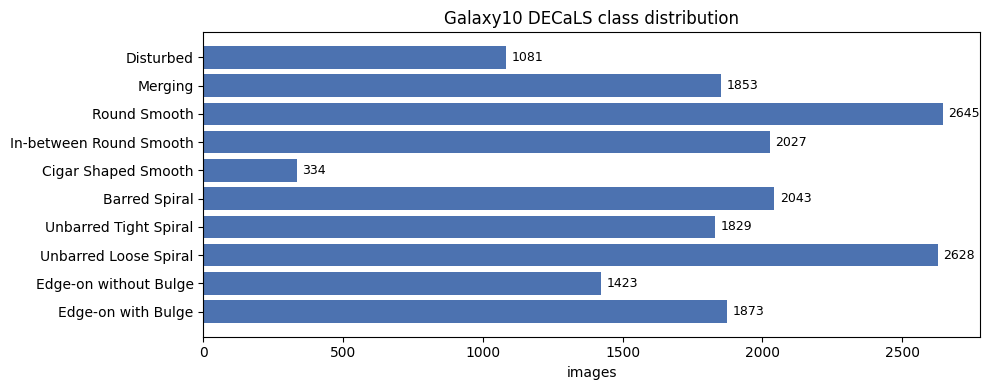

Imbalance ratio (largest / smallest class): 7.9x


In [7]:
counts = np.bincount(labels, minlength=NUM_CLASSES)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(CLASS_NAMES, counts, color="#4C72B0")
for i, c in enumerate(counts):
    ax.text(c + 20, i, str(c), va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("images"); ax.set_title("Galaxy10 DECaLS class distribution")
plt.tight_layout(); plt.savefig(OUT_DIR / "class_distribution.png", dpi=120); plt.show()
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}x")

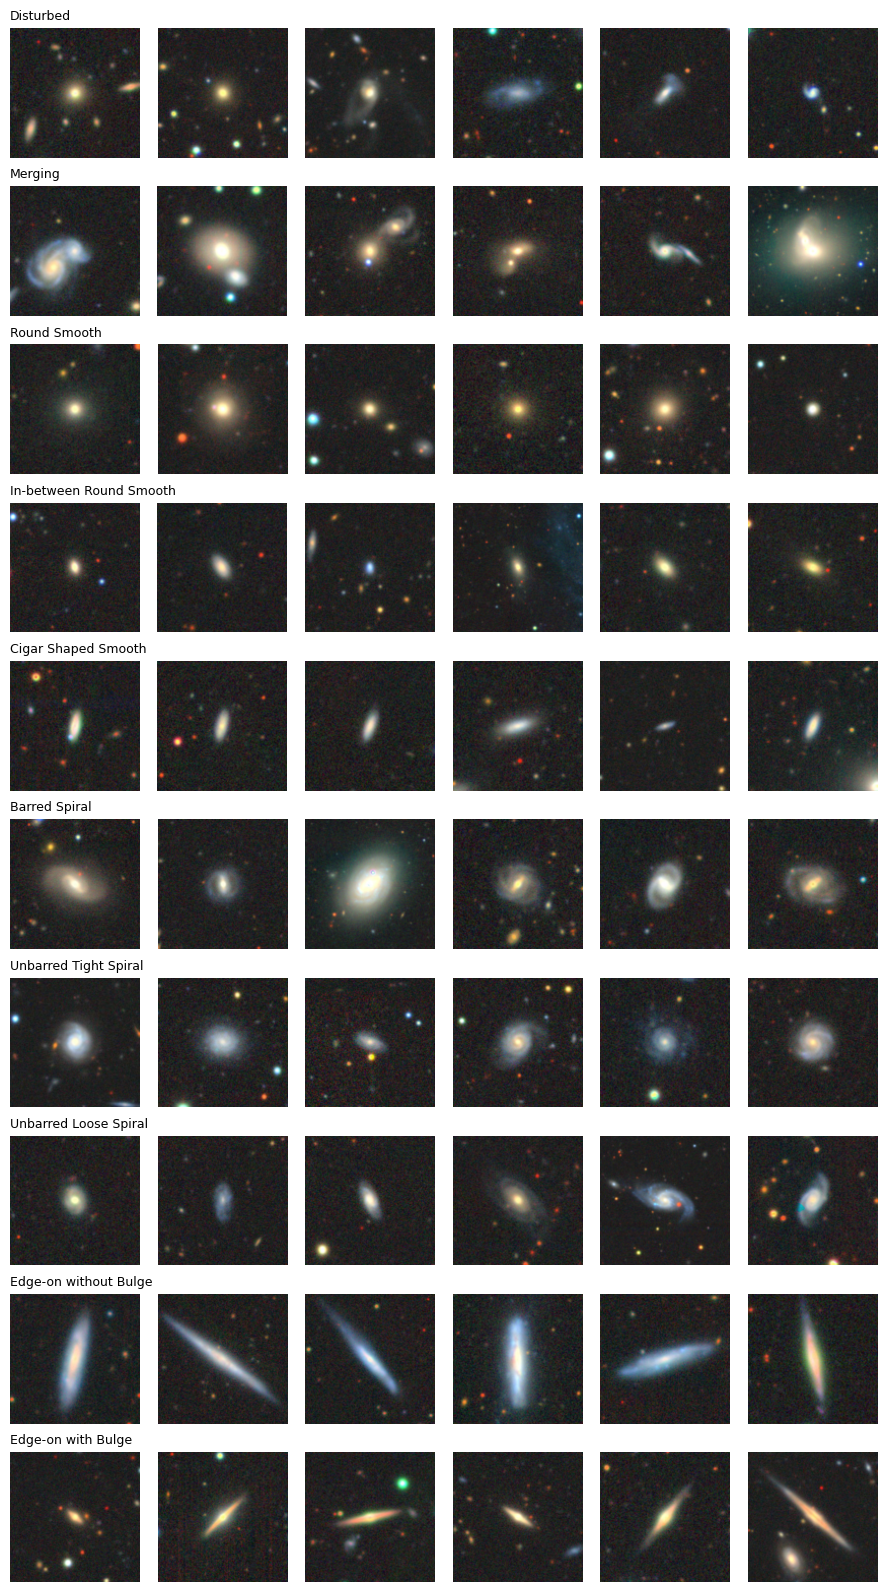

In [8]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(9, 16))
for c in range(NUM_CLASSES):
    cls_idx = np.where(labels == c)[0]
    for j, i in enumerate(rng.choice(cls_idx, size=min(6, len(cls_idx)), replace=False)):
        axes[c, j].imshow(images[i])
    for j in range(6):
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(OUT_DIR / "samples.png", dpi=100); plt.show()

## 6. Stratified train / val / test split
Galaxy10 has no official split, so the split indices are saved with a fixed seed to keep results reproducible.
*Caveat for your report:* the authors note the dataset contains some near-duplicate images, so a small amount of leakage between splits is possible.

In [9]:
all_idx = np.arange(len(labels))
idx_trainval, idx_test = train_test_split(all_idx, test_size=TEST_FRAC, stratify=labels, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                      stratify=labels[idx_trainval], random_state=SEED)
np.savez(OUT_DIR / "split_indices.npz", train=idx_train, val=idx_val, test=idx_test)
print(f"train {len(idx_train)} | val {len(idx_val)} | test {len(idx_test)}")

# Normalisation statistics
if use_pretrained:
    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats for pretrained weights
else:
    sub = images[idx_train[:3000]].astype(np.float32) / 255.0
    MEAN, STD = sub.mean(axis=(0, 1, 2)).tolist(), sub.std(axis=(0, 1, 2)).tolist()
print("mean", np.round(MEAN, 4), "std", np.round(STD, 4))

train 14188 | val 1774 | test 1774
mean [0.1121 0.1094 0.1067] std [0.1236 0.1179 0.1103]


## 7. GPU data pipeline and augmentation
The whole dataset fits in memory, so batches are sliced straight from a tensor and augmented **on the GPU** in a single affine warp: any rotation angle, flip, ±10% zoom, ±5% shift, and brightness jitter.
This keeps a 3060 busy without slow CPU workers, and it avoids the `num_workers` problems Jupyter has on Windows.

In [10]:
mean_t = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(STD, device=device).view(1, 3, 1, 1)

def gpu_augment(x):
    """x: float tensor (B,3,H,W) in [0,1] on device."""
    B, dev = x.shape[0], x.device
    flip = torch.rand(B, device=dev) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    ang = torch.rand(B, device=dev) * 2 * math.pi                      # galaxies are rotation invariant
    scale = torch.empty(B, device=dev).uniform_(0.9, 1.1)
    tx, ty = (torch.empty(B, device=dev).uniform_(-0.05, 0.05) for _ in range(2))
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    x = x * torch.empty(B, 1, 1, 1, device=dev).uniform_(0.85, 1.15)  # brightness
    return x.clamp_(0, 1)

def normalize(x):
    return ((x - mean_t) / std_t).contiguous(memory_format=torch.channels_last)

class GPULoader:
    """Minimal DataLoader replacement for in-memory uint8 images (N,H,W,3)."""
    def __init__(self, imgs, ys, batch_size, shuffle=False, augment=False, drop_last=False, on_gpu=True):
        self.x = torch.from_numpy(np.ascontiguousarray(imgs)).permute(0, 3, 1, 2).contiguous()  # N,3,H,W uint8
        self.y = torch.from_numpy(ys)
        if on_gpu:
            self.x, self.y = self.x.to(device), self.y.to(device)
        self.bs, self.shuffle, self.augment, self.drop_last = batch_size, shuffle, augment, drop_last

    def __len__(self):
        n = len(self.y)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def __iter__(self):
        n = len(self.y)
        order = torch.randperm(n, device=self.x.device) if self.shuffle else torch.arange(n, device=self.x.device)
        for b in range(len(self)):
            sel = order[b * self.bs:(b + 1) * self.bs]
            xb = self.x[sel].to(device, non_blocking=True).float().div_(255)
            yb = self.y[sel].to(device, non_blocking=True)
            if self.augment:
                xb = gpu_augment(xb)
            yield normalize(xb), yb

if DATA_ON_GPU is None:
    DATA_ON_GPU = device.type == "cuda" and images.nbytes < 0.3 * torch.cuda.get_device_properties(0).total_memory
print("Dataset kept on GPU:", DATA_ON_GPU)

train_loader = GPULoader(images[idx_train], labels[idx_train], BATCH_SIZE, shuffle=True,
                         augment=AUGMENT, drop_last=True, on_gpu=DATA_ON_GPU)
val_loader = GPULoader(images[idx_val], labels[idx_val], BATCH_SIZE * 2, on_gpu=DATA_ON_GPU)
test_loader = GPULoader(images[idx_test], labels[idx_test], BATCH_SIZE * 2, on_gpu=DATA_ON_GPU)
print(f"batches/epoch: train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)}")

Dataset kept on GPU: True
batches/epoch: train 221 | val 14 | test 14


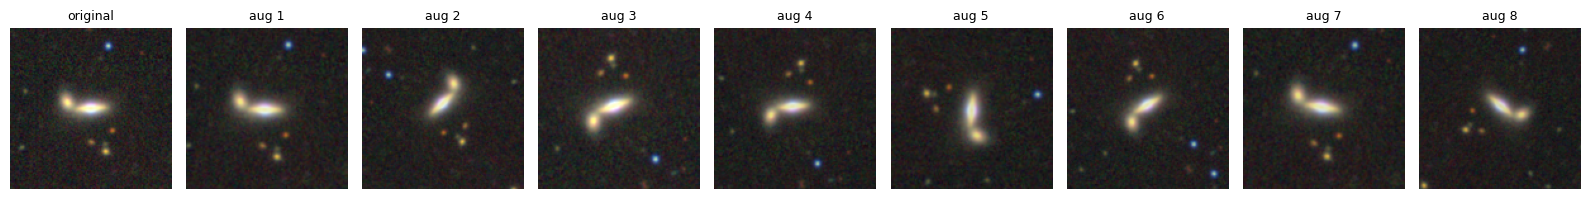

In [11]:
# Preview the augmentation on one image
x0 = torch.from_numpy(images[idx_train[:1]]).permute(0, 3, 1, 2).float().div(255).to(device).repeat(8, 1, 1, 1)
aug = gpu_augment(x0).permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(1, 9, figsize=(16, 2.2))
axes[0].imshow(images[idx_train[0]]); axes[0].set_title("original", fontsize=9)
for i in range(8):
    axes[i + 1].imshow(aug[i]); axes[i + 1].set_title(f"aug {i + 1}", fontsize=9)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 8. Models
**GalaxyNet** is a custom residual CNN with squeeze-and-excitation (channel attention): stem, then 4 stages (64, 128, 256, 384 channels), then global average pooling, dropout and a linear classifier.
The torchvision options give transfer-learning baselines to compare against.

In [12]:
class SE(nn.Module):
    """Squeeze-and-Excitation channel attention."""
    def __init__(self, c, r=8):
        super().__init__()
        self.gate = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(c, c // r, 1), nn.SiLU(),
                                  nn.Conv2d(c // r, c, 1), nn.Sigmoid())
    def forward(self, x):
        return x * self.gate(x)

class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.se = SE(cout)
        self.act = nn.SiLU()
        self.shortcut = nn.Identity() if (stride == 1 and cin == cout) else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = self.act(self.bn1(self.conv1(x)))
        out = self.se(self.bn2(self.conv2(out)))
        return self.act(out + self.shortcut(x))

class GalaxyNet(nn.Module):
    def __init__(self, num_classes=10, widths=(64, 128, 256, 384), depths=(2, 2, 2, 2), drop=0.3):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 32, 3, 1, 1, bias=False), nn.BatchNorm2d(32), nn.SiLU())
        stages, cin = [], 32
        for i, (w, d) in enumerate(zip(widths, depths)):
            blocks = []
            for j in range(d):
                blocks.append(ResBlock(cin, w, stride=2 if (i > 0 and j == 0) else 1))
                cin = w
            stages.append(nn.Sequential(*blocks))
        self.stages = nn.Sequential(*stages)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop), nn.Linear(cin, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        for m in self.modules():                      # zero-init last BN of each residual branch
            if isinstance(m, ResBlock):
                nn.init.zeros_(m.bn2.weight)
    def forward(self, x):
        return self.head(self.stages(self.stem(x)))

def build_model(name, num_classes, pretrained):
    if name == "galaxynet":
        return GalaxyNet(num_classes)
    weights = "DEFAULT" if pretrained else None
    if name in ("resnet18", "resnet50"):
        m = getattr(torchvision.models, name)(weights=weights)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name in ("efficientnet_b0", "convnext_tiny"):
        m = getattr(torchvision.models, name)(weights=weights)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    else:
        raise ValueError(f"unknown model {name}")
    return m

def cam_target_layer(model, name):
    """Last convolutional stage, used by Grad-CAM."""
    return {"galaxynet": lambda m: m.stages[-1], "resnet18": lambda m: m.layer4, "resnet50": lambda m: m.layer4,
            "efficientnet_b0": lambda m: m.features[-1], "convnext_tiny": lambda m: m.features[-1]}[name](model)

model = build_model(MODEL_NAME, NUM_CLASSES, use_pretrained).to(device).to(memory_format=torch.channels_last)
n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME}: {n_params / 1e6:.2f} M parameters")
with torch.no_grad():
    print("output shape:", model(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=device).contiguous(memory_format=torch.channels_last)).shape)

galaxynet: 7.86 M parameters
output shape: torch.Size([2, 10])


## 9. Loss, optimiser and schedule

In [13]:
train_counts = np.bincount(labels[idx_train], minlength=NUM_CLASSES)
if USE_CLASS_WEIGHTS:
    cw = (train_counts.max() / train_counts) ** 0.5   # sqrt inverse frequency: milder than full inverse
    cw = cw / cw.mean()
    class_weights = torch.tensor(cw, dtype=torch.float32, device=device)
    print("class weights:", np.round(cw, 2))
else:
    class_weights = None

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, epochs=EPOCHS,
                                                steps_per_epoch=len(train_loader), pct_start=0.15)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

class weights: [1.15 0.88 0.73 0.84 2.07 0.84 0.88 0.74 1.   0.87]


## 10. Train
The best checkpoint is chosen by **validation macro-F1**, which is fairer than accuracy under class imbalance. You can stop the cell at any time (Kernel → Interrupt) and the best checkpoint so far is kept.

In [14]:
def run_epoch(loader, train):
    model.train(train)
    loss_sum = torch.zeros((), device=device)
    preds, targets = [], []
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(xb)
                loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
            loss_sum += loss.detach() * len(yb)
            preds.append(logits.argmax(1).detach()); targets.append(yb)
    p, t = torch.cat(preds).cpu().numpy(), torch.cat(targets).cpu().numpy()
    return loss_sum.item() / len(t), (p == t).mean(), f1_score(t, p, average="macro")

history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "lr"]}
ckpt_path = OUT_DIR / "best.pt"
best_f1, best_epoch, bad_epochs = -1.0, 0, 0
t_start = time.time()
try:
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        tr_loss, tr_acc, _ = run_epoch(train_loader, train=True)
        va_loss, va_acc, va_f1 = run_epoch(val_loader, train=False)
        cur_lr = optimizer.param_groups[0]["lr"]
        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc, va_f1, cur_lr]):
            history[k].append(float(v))

        mark = ""
        if va_f1 > best_f1:
            best_f1, best_epoch, bad_epochs, mark = va_f1, epoch, 0, "  * saved"
            torch.save({"model": model.state_dict(), "model_name": MODEL_NAME, "img_size": IMG_SIZE,
                        "mean": MEAN, "std": STD, "class_names": CLASS_NAMES,
                        "epoch": epoch, "val_f1": float(va_f1)}, ckpt_path)
        else:
            bad_epochs += 1
        dt = time.time() - t0
        print(f"ep {epoch:3d}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} F1 {va_f1:.3f} | lr {cur_lr:.2e} | {dt:.0f}s{mark}")
        if epoch == 1:
            print(f"  -> estimated total training time: {dt * EPOCHS / 60:.0f} min "
                  f"(first epoch is slower due to cuDNN autotuning)")
        if bad_epochs >= PATIENCE:
            print(f"Early stopping: no val F1 improvement for {PATIENCE} epochs")
            break
except KeyboardInterrupt:
    print("\nInterrupted - keeping best checkpoint so far.")

with open(OUT_DIR / "history.json", "w") as f:
    json.dump(history, f)
print(f"\nDone in {(time.time() - t_start) / 60:.1f} min. Best val macro-F1 {best_f1:.4f} at epoch {best_epoch}")

ep   1/60 | train loss 2.226 acc 0.244 | val loss 2.103 acc 0.349 F1 0.255 | lr 2.07e-04 | 95s  * saved
  -> estimated total training time: 95 min (first epoch is slower due to cuDNN autotuning)
ep   2/60 | train loss 1.924 acc 0.401 | val loss 1.728 acc 0.422 F1 0.356 | lr 4.57e-04 | 101s  * saved
ep   3/60 | train loss 1.672 acc 0.506 | val loss 1.791 acc 0.463 F1 0.386 | lr 8.41e-04 | 100s  * saved
ep   4/60 | train loss 1.540 acc 0.566 | val loss 1.627 acc 0.537 F1 0.453 | lr 1.31e-03 | 103s  * saved
ep   5/60 | train loss 1.433 acc 0.622 | val loss 1.399 acc 0.638 F1 0.580 | lr 1.81e-03 | 117s  * saved
ep   6/60 | train loss 1.369 acc 0.656 | val loss 1.517 acc 0.557 F1 0.535 | lr 2.28e-03 | 121s
ep   7/60 | train loss 1.284 acc 0.687 | val loss 1.903 acc 0.458 F1 0.410 | lr 2.66e-03 | 121s
ep   8/60 | train loss 1.246 acc 0.707 | val loss 1.337 acc 0.697 F1 0.664 | lr 2.91e-03 | 122s  * saved
ep   9/60 | train loss 1.206 acc 0.724 | val loss 1.173 acc 0.729 F1 0.704 | lr 3.00e-03

## 11. Learning curves

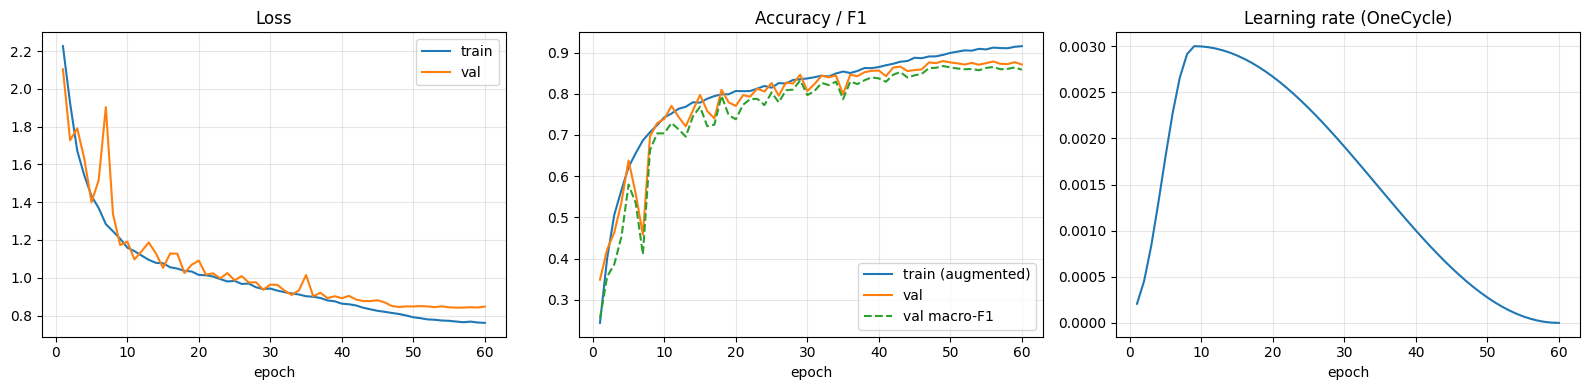

In [15]:
ep = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ep, history["train_loss"], label="train"); axes[0].plot(ep, history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(ep, history["train_acc"], label="train (augmented)"); axes[1].plot(ep, history["val_acc"], label="val")
axes[1].plot(ep, history["val_f1"], label="val macro-F1", ls="--"); axes[1].set_title("Accuracy / F1"); axes[1].legend()
axes[2].plot(ep, history["lr"]); axes[2].set_title("Learning rate (OneCycle)")
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "learning_curves.png", dpi=120); plt.show()

## 12. Test-set evaluation
The best checkpoint is loaded and evaluated on the held-out test set, both plainly and with **test-time augmentation** (the average of the 4 rotations × 2 flips, i.e. the dihedral group D4).

In [16]:
ckpt = torch.load(ckpt_path, map_location=device)
model.load_state_dict(ckpt["model"])
print(f"Loaded best checkpoint from epoch {ckpt['epoch']} (val F1 {ckpt['val_f1']:.4f})")

@torch.no_grad()
def predict(loader, tta=False):
    model.eval()
    probs, ys = [], []
    for xb, yb in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            if tta:
                p = 0
                for k in range(4):
                    xr = torch.rot90(xb, k, dims=(2, 3))
                    p = p + model(xr).float().softmax(1) + model(xr.flip(3)).float().softmax(1)
                p = p / 8
            else:
                p = model(xb).float().softmax(1)
        probs.append(p.cpu()); ys.append(yb.cpu())
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

results = {}
for name, tta in [("plain", False), ("tta", True)]:
    if tta and not USE_TTA:
        continue
    probs, y_true = predict(test_loader, tta=tta)
    y_pred = probs.argmax(1)
    results[name] = {"accuracy": float((y_pred == y_true).mean()),
                     "macro_f1": float(f1_score(y_true, y_pred, average="macro"))}
    print(f"[{name:5s}] test accuracy {results[name]['accuracy']:.4f} | macro-F1 {results[name]['macro_f1']:.4f}")

best_mode = "tta" if "tta" in results else "plain"
probs, y_true = predict(test_loader, tta=(best_mode == "tta"))
y_pred = probs.argmax(1)
print(f"\nClassification report ({best_mode}):\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))

C:\Users\rezwa\AppData\Local\Temp\ipykernel_38028\3500283254.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=device)


Loaded best checkpoint from epoch 49 (val F1 0.8672)
[plain] test accuracy 0.8698 | macro-F1 0.8595
[tta  ] test accuracy 0.8664 | macro-F1 0.8572

Classification report (tta):

                         precision    recall  f1-score   support

              Disturbed      0.713     0.574     0.636       108
                Merging      0.884     0.903     0.893       185
           Round Smooth      0.922     0.940     0.931       265
In-between Round Smooth      0.936     0.941     0.939       203
    Cigar Shaped Smooth      0.833     0.882     0.857        34
          Barred Spiral      0.924     0.833     0.876       204
  Unbarred Tight Spiral      0.735     0.820     0.775       183
  Unbarred Loose Spiral      0.772     0.760     0.766       263
  Edge-on without Bulge      0.944     0.958     0.951       142
     Edge-on with Bulge      0.924     0.973     0.948       187

               accuracy                          0.866      1774
              macro avg      0.859     0

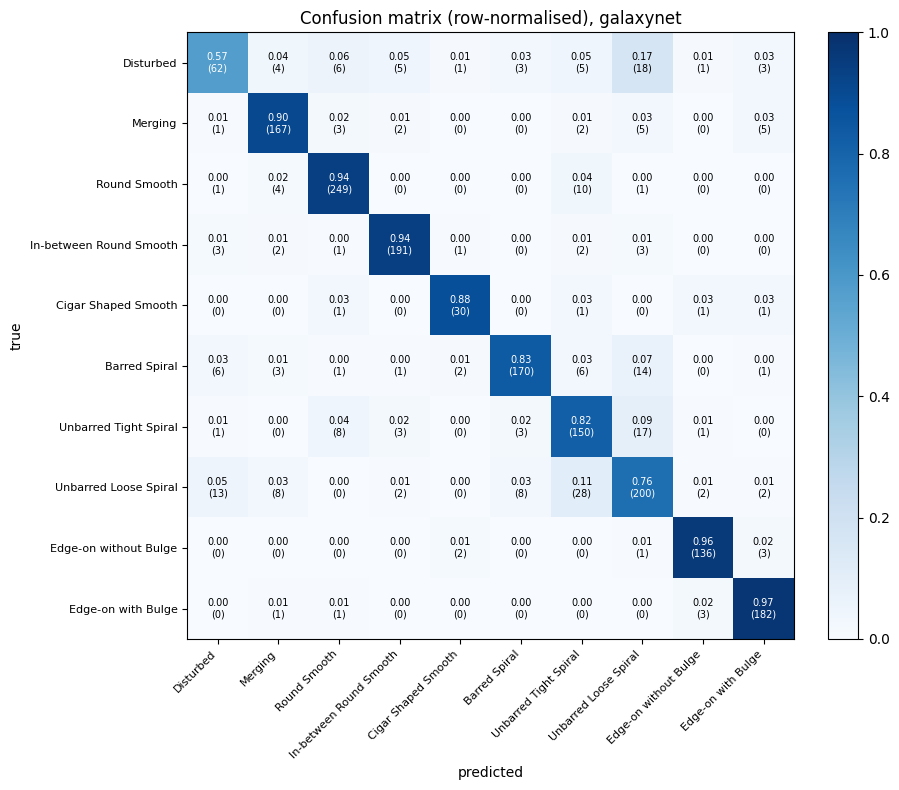

In [17]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=7,
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix (row-normalised), {MODEL_NAME}")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=120); plt.show()

## 13. Misclassified examples

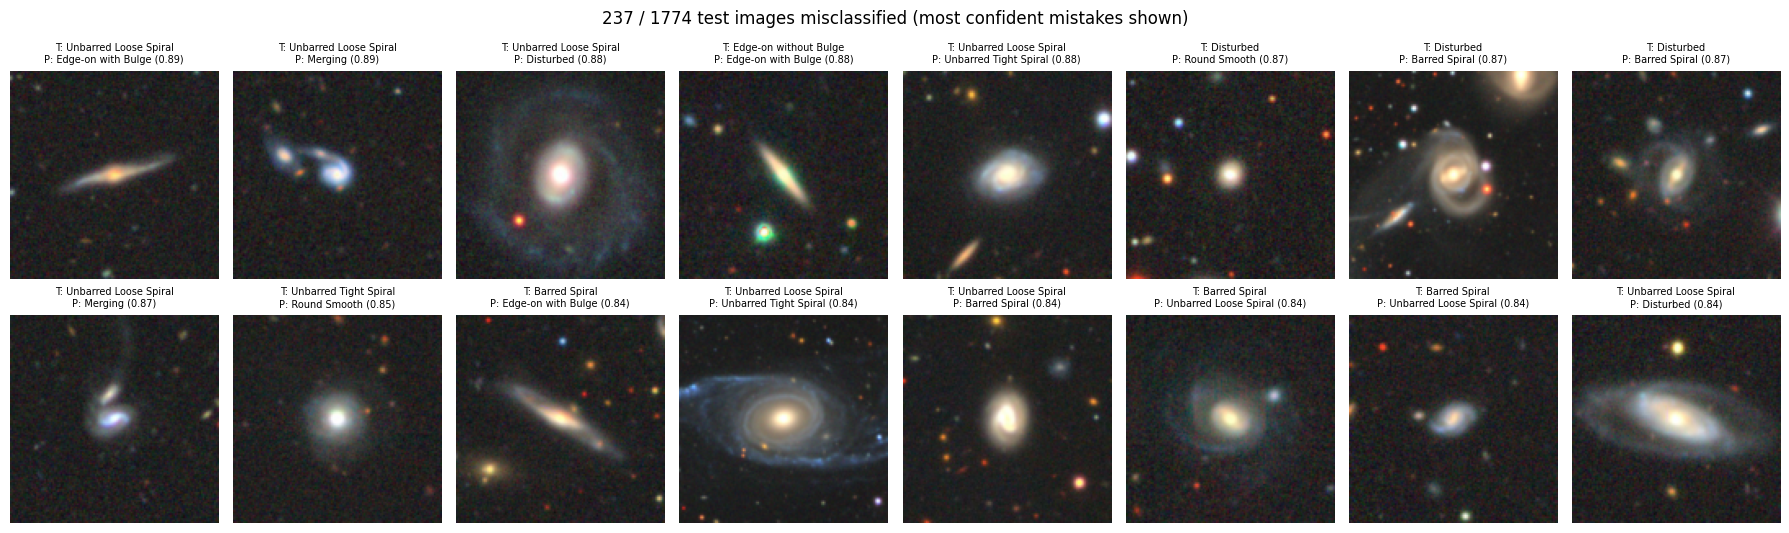

In [18]:
wrong = np.where(y_pred != y_true)[0]
conf = probs.max(1)
show = wrong[np.argsort(-conf[wrong])][:16]          # most confident mistakes first
cols = 8
rows = max(1, math.ceil(len(show) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(18, 2.8 * rows), squeeze=False)
for a in axes.ravel(): a.axis("off")
for a, i in zip(axes.ravel(), show):
    a.imshow(images[idx_test[i]])
    a.set_title(f"T: {CLASS_NAMES[y_true[i]]}\nP: {CLASS_NAMES[y_pred[i]]} ({conf[i]:.2f})", fontsize=7)
plt.suptitle(f"{len(wrong)} / {len(y_true)} test images misclassified (most confident mistakes shown)")
plt.tight_layout(); plt.savefig(OUT_DIR / "misclassified.png", dpi=110); plt.show()

## 14. Grad-CAM: where does the CNN look?
Grad-CAM weights the last convolutional feature maps by their gradients for the predicted class. These maps make good figures for a report: spiral arms, bars, bulges, and merger tails should light up.

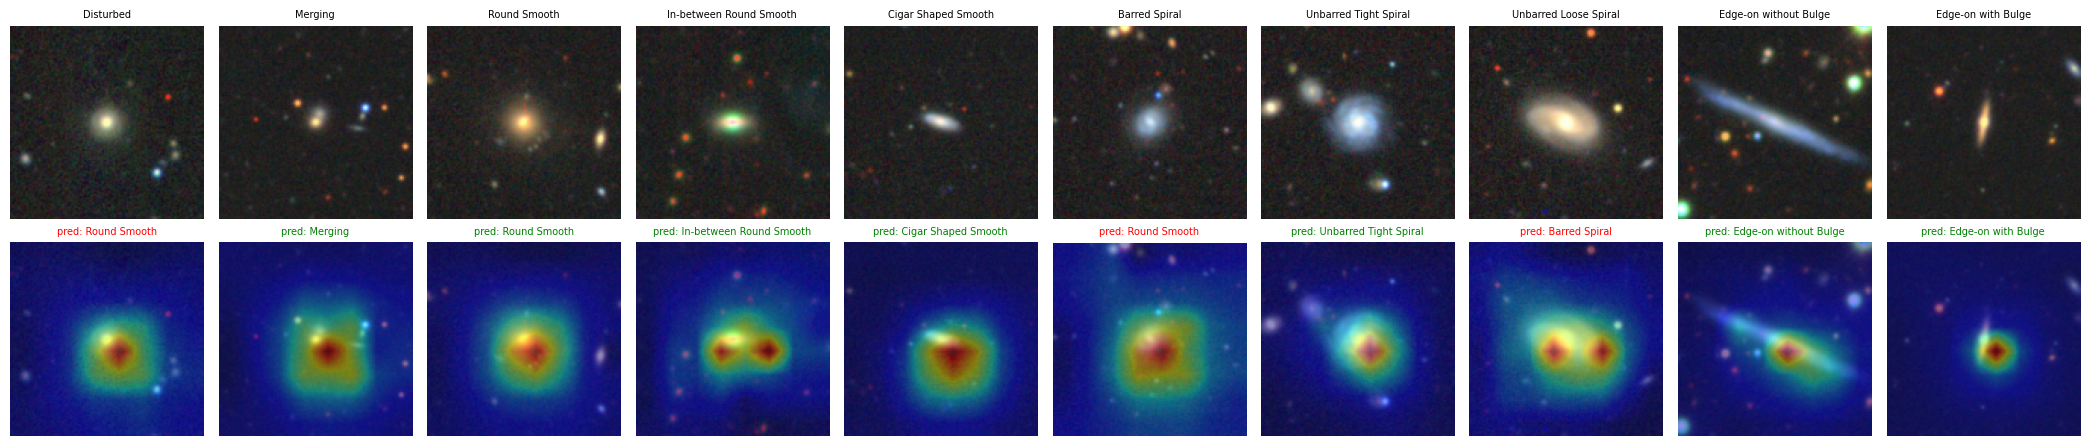

In [19]:
def grad_cam(model, x, layer):
    store = {}
    def fwd_hook(m, i, o):
        store["act"] = o
        o.register_hook(lambda g: store.__setitem__("grad", g))
    h = layer.register_forward_hook(fwd_hook)
    model.eval()
    model.zero_grad(set_to_none=True)
    logits = model(x)                                  # full precision for clean gradients
    pred = logits.argmax(1)
    logits.gather(1, pred[:, None]).sum().backward()
    h.remove()
    w = store["grad"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam - cam.amin(dim=(1, 2), keepdim=True)
    cam = cam / cam.amax(dim=(1, 2), keepdim=True).clamp(min=1e-8)
    return cam.detach().cpu().numpy(), pred.cpu().numpy()

# one test image per class
pick = [idx_test[np.where(labels[idx_test] == c)[0][0]] for c in range(NUM_CLASSES) if (labels[idx_test] == c).any()]
xb = torch.from_numpy(images[pick]).permute(0, 3, 1, 2).float().div(255).to(device)
cams, preds = grad_cam(model, normalize(xb), cam_target_layer(model, MODEL_NAME))
model.zero_grad(set_to_none=True)

fig, axes = plt.subplots(2, len(pick), figsize=(2.1 * len(pick), 4.6))
for k, i in enumerate(pick):
    axes[0, k].imshow(images[i]); axes[0, k].set_title(CLASS_NAMES[labels[i]], fontsize=7)
    axes[1, k].imshow(images[i]); axes[1, k].imshow(cams[k], cmap="jet", alpha=0.45)
    axes[1, k].set_title(f"pred: {CLASS_NAMES[preds[k]]}", fontsize=7,
                         color="green" if preds[k] == labels[i] else "red")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "gradcam.png", dpi=120); plt.show()

## 15. Save summary

In [20]:
summary = {
    "model": MODEL_NAME, "pretrained": use_pretrained, "img_size": IMG_SIZE, "params_M": round(n_params / 1e6, 2),
    "epochs_run": len(history["train_loss"]), "best_epoch": best_epoch, "best_val_macro_f1": round(best_f1, 4),
    "test": results, "batch_size": BATCH_SIZE, "lr": lr, "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING, "class_weights": USE_CLASS_WEIGHTS, "augment": AUGMENT, "seed": SEED,
}
with open(OUT_DIR / "results.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("\nAll figures, the checkpoint and results are in:", OUT_DIR.resolve())

{
  "model": "galaxynet",
  "pretrained": false,
  "img_size": 128,
  "params_M": 7.86,
  "epochs_run": 60,
  "best_epoch": 49,
  "best_val_macro_f1": 0.8672,
  "test": {
    "plain": {
      "accuracy": 0.8697857948139797,
      "macro_f1": 0.8595013658956205
    },
    "tta": {
      "accuracy": 0.8664036076662909,
      "macro_f1": 0.8572236082316064
    }
  },
  "batch_size": 64,
  "lr": 0.003,
  "weight_decay": 0.05,
  "label_smoothing": 0.1,
  "class_weights": true,
  "augment": true,
  "seed": 42
}

All figures, the checkpoint and results are in: F:\pyx\runs\galaxynet_128px


## Ideas for the report
- **Scratch vs transfer learning:** run `galaxynet` @128px, then `resnet50` @224px pretrained, and compare accuracy, F1, parameter count and training time.
- **Ablations:** turn off `AUGMENT` (expect strong overfitting), `USE_CLASS_WEIGHTS`, or `LABEL_SMOOTHING`, and compare the per-class F1 of the rare *Cigar Shaped Smooth* class.
- **Rotation invariance:** report the plain vs TTA gap. Galaxies have no orientation, so averaging over rotations should help.
- **Error analysis:** use the confusion matrix. Which classes get confused (e.g. Round Smooth vs In-between, Tight vs Loose spiral), and do those classes also look ambiguous to the human volunteers?
- **Interpretability:** Grad-CAM figures showing what the CNN attends to.